In [1]:
import sklearn.cluster
import scipy.spatial
import matplotlib


def cluster_trajs(trajs, n_clusters, cluster_centers):
    trajs_concat = np.concatenate(trajs)

    if cluster_centers is None:
        clustering_model = sklearn.cluster.KMeans(
            n_clusters=n_clusters,
            init="k-means++",
            n_init=10,
            max_iter=int(1e10),
            tol=1e-10,
            verbose=0,
            random_state=1,
            copy_x=True,
            algorithm="lloyd"
        )
        clustering_model.fit(trajs_concat)
        cluster_centers = clustering_model.cluster_centers_

    clustered_trajs_concat = scipy.spatial.cKDTree(cluster_centers).query(trajs_concat)[1]
    return clustered_trajs_concat.reshape(len(trajs), N_TIMESTEP_IN_REPLICA), cluster_centers


def plot_clusters_1d(ax, trajs, clustered_trajs, cluster_centers):
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = np.concatenate(clustered_trajs)

    ax.hist(trajs_concat, bins=n_clusters*5)
    for cluster_center in cluster_centers:
        ax.axvline(x=cluster_center, color="black", linewidth=0.2)


def plot_clusters_2d(ax, trajs, clustered_trajs, cluster_centers):
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = np.concatenate(clustered_trajs)

    ax.scatter(trajs_concat[:, 0], trajs_concat[:, 1], s=0.1, c=[matplotlib.cm.tab20(i_cluster%20) for i_cluster in clustered_trajs_concat])
    for cluster_center in cluster_centers:
        ax.scatter(cluster_center[0], cluster_center[1], color="black", s=5)

In [2]:
import deeptime.markov
import deeptime.markov.msm
import deeptime.util.validation
import deeptime.plots
from deeptime.markov._base import MembershipsObservable
from deeptime.util.validation import ChapmanKolmogorovTest
from matplotlib.lines import Line2D


def construct_msm(clustered_trajs, lagtimes):
    msm_models = {}
    stationary_distributions = {}

    for lagtime in lagtimes:
        count_estimator = deeptime.markov.TransitionCountEstimator(
            lagtime=lagtime,
            count_mode="sliding",
            n_states=None,
            sparse=False,
        )
        count_estimator.fit(clustered_trajs)
        count_model = count_estimator.fetch_model()

        msm_constructor = deeptime.markov.msm.MaximumLikelihoodMSM(
            reversible=True,
            stationary_distribution_constraint=None,
            sparse=False,
            allow_disconnected=False,
            maxiter=int(1e10),
            maxerr=1e-10,
            connectivity_threshold=0,
            transition_matrix_tolerance=1e-10,
            lagtime=None,
            use_lcc=True,
        ) 

        try:
            msm_constructor.fit(count_model)
        except Exception as e:
            print(f"MSM construction error lagtime {lagtime}: {e}")
            continue

        msm_models[lagtime] = msm_constructor.fetch_model()
        stationary_distributions[lagtime] = np.zeros(np.max(clustered_trajs)+1)
        stationary_distributions[lagtime][msm_models[lagtime].count_model.state_symbols] = msm_models[lagtime].stationary_distribution

    return msm_models, stationary_distributions


def plot_implied_timescales(ax, msm_models):
    deeptime.plots.plot_implied_timescales(
        data=deeptime.util.validation.implied_timescales(list(msm_models.values())),
        n_its=10,
        process=None,
        show_mle=True,
        show_samples=True,
        show_sample_mean=True,
        show_sample_confidence=True,
        show_cutoff=True,
        sample_confidence=0.95,
        colors=None,
        ax=ax
    )
    ax.set_xlim(0, np.max(list(msm_models.keys())))
    ax.set_yscale("log")


def perform_ck_test(clustered_trajs_reference, msm_models_reference, clustered_trajs_bootstrap, msm_models_bootstrap, lagtime, n_metastable_sets, conf=0.95, tolerance=0.05):
    def draw_ck_test(ck_test, is_markovian, conf=0.95):
        grid = deeptime.plots.plot_ck_test(ck_test, conf=conf, legend=False, y01=False, sharey=False)
        grid.figure.legend(
            handles=[Line2D([], [], color="black", label="estimate"), Line2D([], [], color="C0", ls="--", label="predict")],
            loc="upper center",
            ncols=2,
            frameon=False,
            title=f"Markovian: {is_markovian}"
        )
        plt.show()

    ck_models_reference, _ = construct_msm(clustered_trajs_reference, [lagtime*k for k in range(1, 5) if lagtime*k < N_TIMESTEP_IN_REPLICA - 1])
    ck_lagtimes = list(ck_models_reference)
    if len(ck_lagtimes) < 2:
        return None

    is_bootstrap = clustered_trajs_bootstrap is not None and msm_models_bootstrap is not None
    test_model_reference = msm_models_reference[lagtime]
    n_states_full = max(msm_models[lagtime].count_model.n_states_full for msm_models in [msm_models_reference, *(msm_models_bootstrap if is_bootstrap else [])])
    memberships = np.zeros((n_states_full, n_metastable_sets))
    memberships[test_model_reference.count_model.state_symbols] = test_model_reference.pcca(n_metastable_sets).memberships

    def calculate_ck_test(ck_models, msm_models):
        test_model = msm_models[lagtime]
        observable = MembershipsObservable(test_model, memberships[test_model.count_model.state_symbols])
        return deeptime.util.validation.ck_test([ck_models[ck_lagtime] for ck_lagtime in ck_lagtimes], observable, test_model=test_model)

    ck_test_reference = calculate_ck_test(ck_models_reference, msm_models_reference)
    checked = lagtime < ck_test_reference.lagtimes

    if not is_bootstrap:
        differences = np.real(ck_test_reference.predictions - ck_test_reference.estimates)[checked]
        passed = np.abs(differences) <= tolerance
        is_markovian = bool(np.all(passed))
        for i_lagtime, i, j in zip(*np.where(~passed)):
            print(f"lag {ck_test_reference.lagtimes[checked][i_lagtime]}: {i+1} -> {j+1}", f"predict-estimate: {differences[i_lagtime, i, j]:+.4f}")

        draw_ck_test(ck_test_reference, is_markovian)
        return is_markovian

    ck_tests_bootstrap = []
    for i_bootstrap, (clustered_trajs, msm_models) in enumerate(zip(clustered_trajs_bootstrap, msm_models_bootstrap)):
        ck_models, _ = construct_msm(clustered_trajs, ck_lagtimes)
        if all(ck_lagtime in ck_models for ck_lagtime in ck_lagtimes):
            ck_tests_bootstrap.append(calculate_ck_test(ck_models, msm_models))
        else:
            print(f"error bootstrap {i_bootstrap}, lag {ck_lagtimes}")
    if len(ck_tests_bootstrap) < 2:
        return None

    i_lagtimes = range(len(ck_test_reference.lagtimes))
    ck_test = ChapmanKolmogorovTest(
        ck_test_reference.lagtimes,
        ck_test_reference.predictions,
        [[ck_test_bootstrap.predictions[i_lagtime] for ck_test_bootstrap in ck_tests_bootstrap] for i_lagtime in i_lagtimes],
        ck_test_reference.estimates,
        [[ck_test_bootstrap.estimates[i_lagtime] for ck_test_bootstrap in ck_tests_bootstrap] for i_lagtime in i_lagtimes],
        None,
    )

    differences = np.real(np.array(ck_test.predictions_samples) - np.array(ck_test.estimates_samples))[checked]
    with np.errstate(invalid="ignore"):
        differences_lower, differences_upper = np.nanpercentile(differences, [50*(1-conf), 50*(1+conf)], axis=1)
    passed = (differences_lower <= tolerance) & (-tolerance <= differences_upper)
    passed |= np.isnan(differences_lower)
    is_markovian = bool(np.all(passed))
    for i_lagtime, i, j in zip(*np.where(~passed)):
        print(
            f"lag {ck_test.lagtimes[checked][i_lagtime]}: {i+1} -> {j+1}",
            f"predict-estimate: [{differences_lower[i_lagtime, i, j]:+.4f}, {differences_upper[i_lagtime, i, j]:+.4f}]"
        )

    draw_ck_test(ck_test, is_markovian, conf=conf)
    return is_markovian

In [3]:
import scipy.constants
import scipy.spatial
import warnings


def calculate_pmf(stationary_distribution, stationary_distributions_bootstrap):
    def _calculate_pmf(_stationary_distribution):
        stationary_distribution_full = np.zeros(len(stationary_distribution))
        stationary_distribution_full[:len(_stationary_distribution)] = _stationary_distribution

        with np.errstate(divide="ignore"):
            pmf = -np.log(stationary_distribution_full/np.max(stationary_distribution_full))
        pmf[~np.isfinite(pmf)] = np.nan
        pmf *= scipy.constants.Boltzmann
        pmf *= TEMPERATURE
        pmf *= scipy.constants.Avogadro
        pmf /= scipy.constants.calorie
        pmf /= 1000
        return pmf

    pmf = _calculate_pmf(stationary_distribution)
    if stationary_distributions_bootstrap is None:
        return pmf, None

    pmfs_bootstrap = np.array([_calculate_pmf(_stationary_distribution) for _stationary_distribution in stationary_distributions_bootstrap]).reshape(-1, len(stationary_distribution))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        pmf_std = np.nanstd(pmfs_bootstrap, axis=0, ddof=1)

    return pmf, pmf_std


def calculate_pmf_plot(cluster_centers, pmf, pmf_std, unbound_threshold):
    com_distances_cluster_centers = np.linalg.norm(cluster_centers, axis=1)
    indices_order = np.argsort(com_distances_cluster_centers)
    pmf_baseline = np.nanmean(pmf[unbound_threshold < com_distances_cluster_centers])

    ordered_cluster_centers = com_distances_cluster_centers[indices_order]
    ordered_pmf = pmf[indices_order] - pmf_baseline
    ordered_pmf_std = pmf_std[indices_order] if pmf_std is not None else None

    return ordered_cluster_centers, ordered_pmf, ordered_pmf_std


def plot_pmf(ax, ordered_cluster_centers, ordered_pmf, ordered_pmf_std, xmin, xmax, ymin, ymax, bound_threshold=None, unbound_threshold=None):
    ax.hlines(0, xmin=xmin, xmax=xmax, color="black")
    if bound_threshold is not None and unbound_threshold is not None:
        ax.vlines(bound_threshold,   ymin=ymin, ymax=ymax, color="black", linestyles="--")
        ax.vlines(unbound_threshold, ymin=ymin, ymax=ymax, color="black", linestyles="--")

    if ordered_pmf_std is not None:
        ax.fill_between(ordered_cluster_centers, ordered_pmf-ordered_pmf_std, ordered_pmf+ordered_pmf_std, alpha=0.3)
    ax.plot(ordered_cluster_centers, ordered_pmf)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)


def calculate_g_pmf(cluster_centers, stationary_distribution, stationary_distributions_bootstrap, bound_threshold, unbound_threshold):
    com_distances_cluster_centers = np.linalg.norm(cluster_centers, axis=1)
    bound = com_distances_cluster_centers < bound_threshold
    unbound = unbound_threshold < com_distances_cluster_centers

    def _calculate_g_pmf(_stationary_distribution):
        stationary_distribution_full = np.zeros(len(cluster_centers))
        stationary_distribution_full[:len(_stationary_distribution)] = _stationary_distribution

        with np.errstate(divide="ignore", invalid="ignore"):
            g_pmf = -np.log(stationary_distribution_full[bound].sum()/stationary_distribution_full[unbound].sum())
        if not np.isfinite(g_pmf):
            return np.nan
        g_pmf *= scipy.constants.Boltzmann
        g_pmf *= TEMPERATURE
        g_pmf *= scipy.constants.Avogadro
        g_pmf /= scipy.constants.calorie
        g_pmf /= 1000
        return g_pmf

    g_pmf = _calculate_g_pmf(stationary_distribution)
    if stationary_distributions_bootstrap is None:
        return g_pmf, None

    g_pmfs_bootstrap = np.array([_calculate_g_pmf(_stationary_distribution) for _stationary_distribution in stationary_distributions_bootstrap])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        g_pmf_std = np.nanstd(g_pmfs_bootstrap, ddof=1)

    return g_pmf, g_pmf_std


def calculate_volume_correction(com_vectors, unbound_threshold):
    unbound_com_vectors = com_vectors[unbound_threshold < np.linalg.norm(com_vectors, axis=2)]
    if len(unbound_com_vectors) == 0:
        return 0

    hull = scipy.spatial.ConvexHull(unbound_com_vectors)

    volume_correction = -np.log(hull.volume/1.661)
    volume_correction *= scipy.constants.Boltzmann
    volume_correction *= TEMPERATURE
    volume_correction *= scipy.constants.Avogadro
    volume_correction /= scipy.constants.calorie
    volume_correction /= 1000

    return volume_correction


def calculate_k_off(cluster_centers, msm_model, msm_models_bootstrap, bound_threshold, unbound_threshold):
    com_distances_cluster_centers = np.linalg.norm(cluster_centers, axis=1)
    bound = np.where(com_distances_cluster_centers < bound_threshold)[0]
    unbound = np.where(unbound_threshold < com_distances_cluster_centers)[0]

    def _calculate_k_off(_msm_model):
        origin = _msm_model.count_model.symbols_to_states(bound)
        target = _msm_model.count_model.symbols_to_states(unbound)
        if len(origin) == 0 or len(target) == 0:
            return np.nan

        mfpt = deeptime.markov.tools.analysis.mfpt(
            T=_msm_model.transition_matrix,
            target=target,
            origin=origin,
            tau=_msm_model.lagtime * 1e-12,
            mu=_msm_model.stationary_distribution,
        )
        return 1 / mfpt if 0 < mfpt else np.nan

    k_off = _calculate_k_off(msm_model)
    if msm_models_bootstrap is None:
        return k_off, None

    k_offs_bootstrap = np.array([_calculate_k_off(_msm_model) for _msm_model in msm_models_bootstrap])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        k_off_std = np.nanstd(k_offs_bootstrap, ddof=1)

    return k_off, k_off_std

In [4]:
import pickle
import os
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt


N_TIMESTEP_IN_REPLICA = 101
TEMPERATURE = 300

pickle_dir = "./pickle-cache/energy_dissociation_3d_trial"
if not os.path.exists(pickle_dir):
    os.mkdir(pickle_dir)

pacs_com_distances = []
pacs_com_vectors = []
for trial in range(50):
    pickle_com_distances = pickle.load(open(f"./pickle-cache/com-features/pacs_com_distances_{trial}.pickle", "rb"))
    pacs_com_distances.append(pickle_com_distances.reshape((-1, N_TIMESTEP_IN_REPLICA, 1)))
    pickle_com_vectors = pickle.load(open(f"./pickle-cache/com-features/pacs_com_vectors_{trial}.pickle", "rb"))
    pacs_com_vectors.append(pickle_com_vectors.reshape((-1, N_TIMESTEP_IN_REPLICA, 3)))

trajs = pacs_com_vectors




In [5]:
n_clusters_candidates = [80, 70, 60, 50, 40]

if False:
    clustered_trajs = [None for _ in range(len(trajs))]
    cluster_centers = [None for _ in range(len(trajs))]

    for trial in range(len(trajs)):
        clustered_trajs[trial] = {}
        cluster_centers[trial] = {}
        for i_clusters, n_clusters in enumerate(n_clusters_candidates):
            print(trial, n_clusters)
            clustered_trajs[trial][n_clusters], cluster_centers[trial][n_clusters] = cluster_trajs(trajs[trial], n_clusters, None)

    pickle.dump(clustered_trajs, open(f"{pickle_dir}/clustered_trajs.pickle", "wb"))
    pickle.dump(cluster_centers, open(f"{pickle_dir}/cluster_centers.pickle", "wb"))
else:
    clustered_trajs = pickle.load(open(f"{pickle_dir}/clustered_trajs.pickle", "rb"))
    cluster_centers = pickle.load(open(f"{pickle_dir}/cluster_centers.pickle", "rb"))


fig, ax = plt.subplots(len(trajs), len(n_clusters_candidates))
fig.set_size_inches(len(n_clusters_candidates)*4, len(trajs)*4)

for trial in range(len(trajs)):
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        plot_clusters_2d(ax[trial][i_clusters], trajs[trial][::10], clustered_trajs[trial][n_clusters][::10], cluster_centers[trial][n_clusters])
        ax[trial][i_clusters].set_title(f"{trial}-{n_clusters}")




In [6]:
if False:
    msm_models = [None for _ in range(len(trajs))]
    stationary_distributions = [None for _ in range(len(trajs))]

    for trial in range(len(trajs)):
        msm_models[trial] = {}
        stationary_distributions[trial] = {}
        for i_clusters, n_clusters in enumerate(n_clusters_candidates):
            print(trial, n_clusters)
            msm_models[trial][n_clusters], stationary_distributions[trial][n_clusters] = construct_msm(clustered_trajs[trial][n_clusters], range(2, int(N_TIMESTEP_IN_REPLICA/2), 2))

    pickle.dump(msm_models, open(f"{pickle_dir}/msm_models.pickle", "wb"))
    pickle.dump(stationary_distributions, open(f"{pickle_dir}/stationary_distributions.pickle", "wb"))
else:
    msm_models = pickle.load(open(f"{pickle_dir}/msm_models.pickle", "rb"))
    stationary_distributions = pickle.load(open(f"{pickle_dir}/stationary_distributions.pickle", "rb"))


fig, ax = plt.subplots(len(trajs), len(n_clusters_candidates))
fig.set_size_inches(len(n_clusters_candidates)*4, len(trajs)*4)

for trial in range(len(trajs)):
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        plot_implied_timescales(ax[trial][i_clusters], msm_models[trial][n_clusters])
        ax[trial][i_clusters].set_title(f"{trial}-{n_clusters}")

In [7]:
for trial in range(len(trajs)):
    for n_clusters in msm_models[trial]:
        for lagtime in msm_models[trial][n_clusters]:
            if not deeptime.markov.tools.analysis.is_reversible(msm_models[trial][n_clusters][lagtime].transition_matrix, mu=None, tol=1e-12):
                print(trial, n_clusters, lagtime)

In [8]:
# n_metastable_sets = 2
# for trial in range(len(trajs)):
#     for n_clusters in msm_models[0]:
#         for lagtime in range(10, 41, 10):
#             print(trial, n_clusters, lagtime, perform_ck_test(clustered_trajs[trial][n_clusters], msm_models[trial][n_clusters], None, None, lagtime, n_metastable_sets))




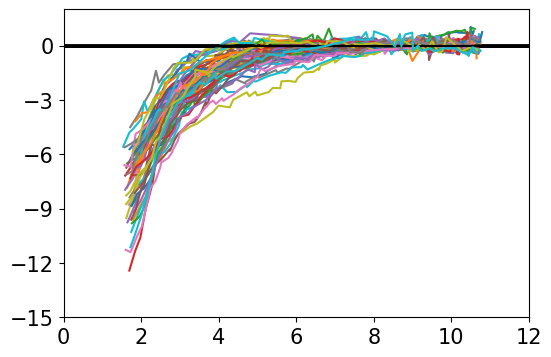

In [9]:
N_CLUSTERS = [60 for _ in range(len(trajs))]
LAGTIMES   = [20 for _ in range(len(trajs))]

BOUND_THRESHOLDS = [2.2 for _ in range(len(trajs))]
UNBOUND_THRESHOLDS = [
    6.5, 4.5, 5, 5.5, 3.5,
    4, 5, 4, 5, 4.5,
    3, 5, 5, 7, 7,
    5.5, 6, 6.5, 6, 7,
    7, 6, 6, 4.5, 4.5,
    4.5, 7, 8, 8, 8,
    6, 5, 5.5, 5.5, 7,
    6, 5, 5.5, 3.5, 4,
    5, 5, 5, 5, 5.5,
    6, 8, 5.5, 5.5,6,
]


fig_trial, ax_trial = plt.subplots(1, len(trajs))
fig_trial.set_size_inches(3*len(trajs), 2)

fig_all, ax_all = plt.subplots(1,1)
fig_all.set_size_inches(6, 4)

ax_all.hlines(0, xmin=0, xmax=12, color="black", linewidth=2)

for trial in range(len(trajs)):
    pmf, _ = calculate_pmf(stationary_distributions[trial][N_CLUSTERS[trial]][LAGTIMES[trial]], None)
    ordered_cluster_centers, ordered_pmf, _ = calculate_pmf_plot(cluster_centers[trial][N_CLUSTERS[trial]], pmf, None, UNBOUND_THRESHOLDS[trial])

    plot_pmf(ax_all,          ordered_cluster_centers, ordered_pmf, None, 0, 12, -15, 2)
    plot_pmf(ax_trial[trial], ordered_cluster_centers, ordered_pmf, None, 0, 12, -15, 2, bound_threshold=BOUND_THRESHOLDS[trial], unbound_threshold=UNBOUND_THRESHOLDS[trial])
    ax_trial[trial].set_title(trial)

ax_all.set_xticks(range(0, 13, 2))
ax_all.tick_params(axis='x', labelsize=15)
ax_all.set_yticks(range(-15, 3, 3))
ax_all.tick_params(axis='y', labelsize=15)

In [10]:
g_pmfs = np.zeros(len(trajs))
volume_corrections = np.zeros(len(trajs))
for trial in range(len(trajs)):
    g_pmfs[trial], _ = calculate_g_pmf(cluster_centers[trial][N_CLUSTERS[trial]], stationary_distributions[trial][N_CLUSTERS[trial]][LAGTIMES[trial]], None, BOUND_THRESHOLDS[trial], UNBOUND_THRESHOLDS[trial])
    volume_corrections[trial] = calculate_volume_correction(pacs_com_vectors[trial], UNBOUND_THRESHOLDS[trial])

gs = g_pmfs + volume_corrections

for trial in range(len(trajs)):
    print(trial, g_pmfs[trial], volume_corrections[trial], gs[trial])
print()
print("mean", gs.mean())
print("std ", gs.std())

pickle.dump(gs, open(f"{pickle_dir}/gs.pickle", "wb"))

0 -3.822913768536429 -2.3871992530499293 -6.210113021586358
1 -5.854414815557393 -2.4976901419156614 -8.352104957473054
2 -4.778821483544491 -2.4539222137868695 -7.232743697331361
3 -5.132400924456297 -2.466881571697952 -7.599282496154249
4 -5.870760134085447 -2.4926922756813172 -8.363452409766765
5 -4.687008260138343 -2.403804706135614 -7.090812966273957
6 -6.773281659569277 -2.6743866041867324 -9.44766826375601
7 -2.400691345799169 -2.6025299430829576 -5.003221288882127
8 -7.417089828792335 -2.608093654347719 -10.025183483140054
9 -3.5958052264331917 -2.6559750223365155 -6.251780248769707
10 -3.9268809801612914 -2.7318588108974065 -6.658739791058698
11 -7.644385284768655 -2.4865123674537215 -10.130897652222377
12 -6.731994727760392 -2.492173279415948 -9.22416800717634
13 -10.450140116050534 -2.3736774645395387 -12.823817580590072
14 -7.816270083662801 -2.3954939253609138 -10.211764009023716
15 -4.929334531586924 -2.2428921983581582 -7.172226729945082
16 -5.1954854328479385 -2.3970155

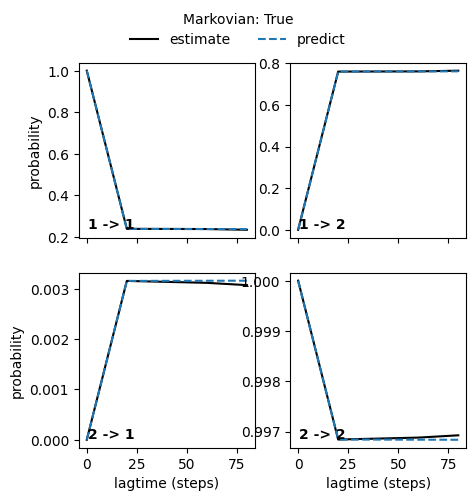

0 True


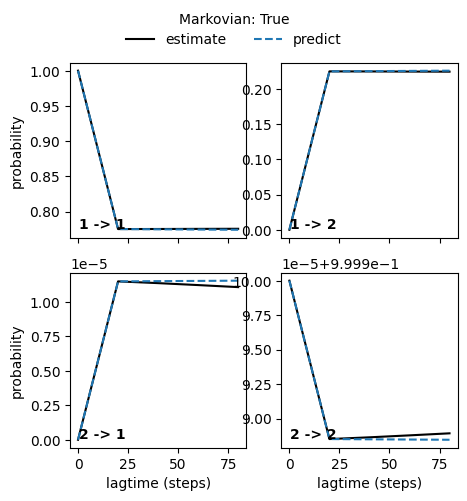

1 True


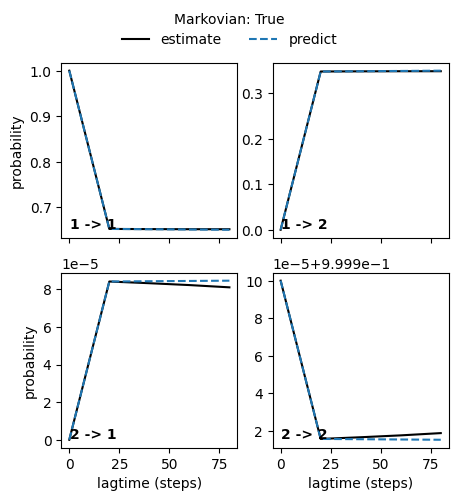

2 True


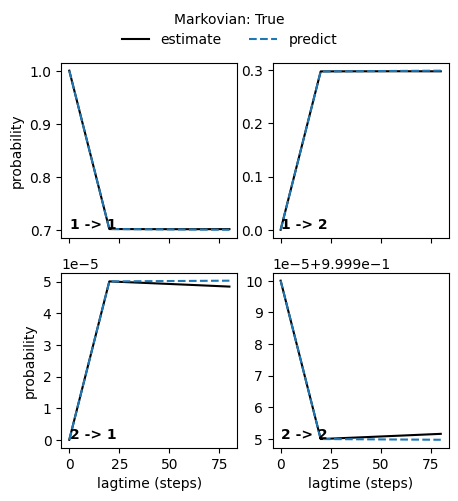

3 True


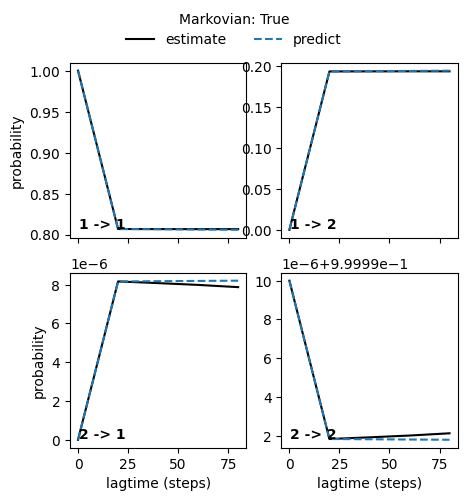

4 True


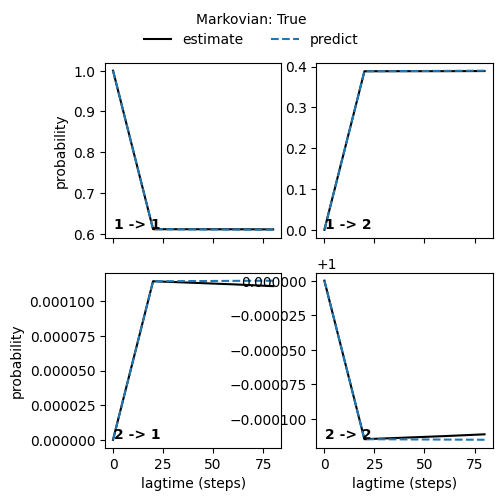

5 True


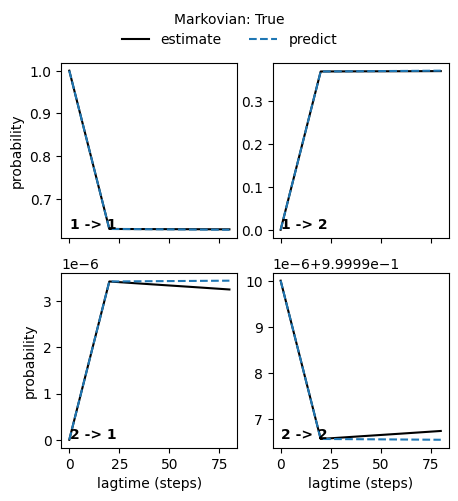

6 True


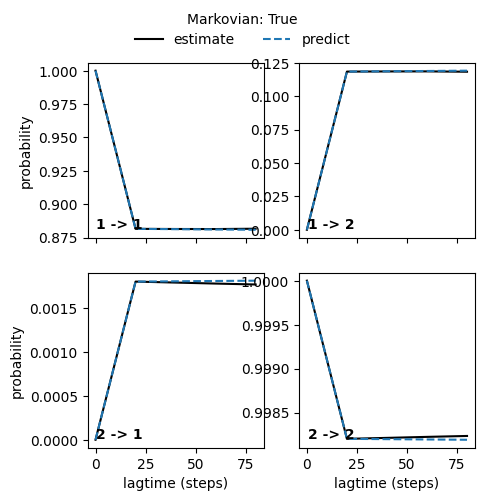

7 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


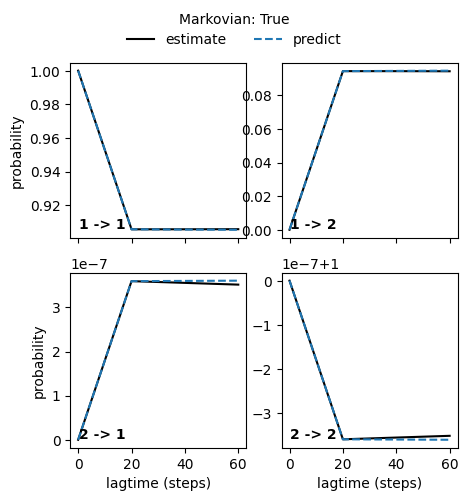

8 True


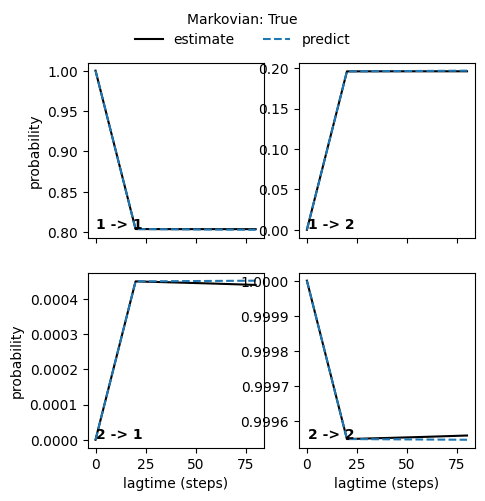

9 True


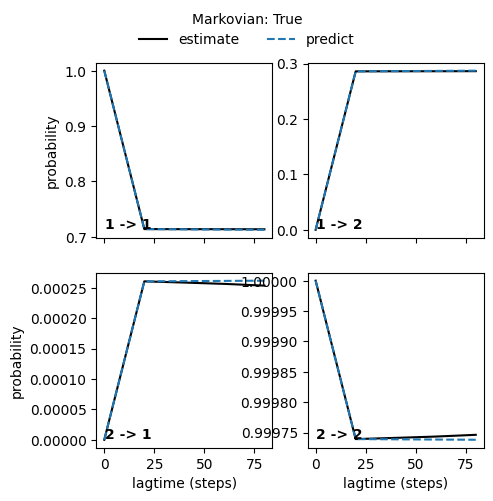

10 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


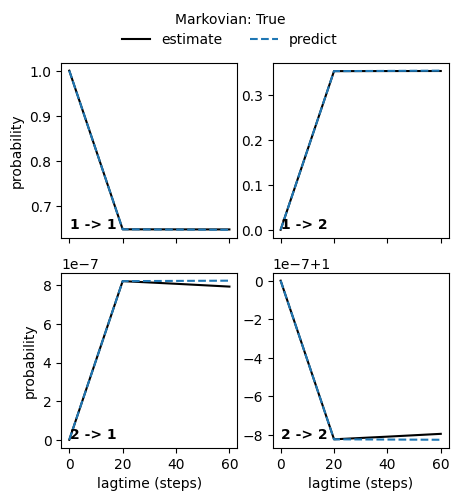

11 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


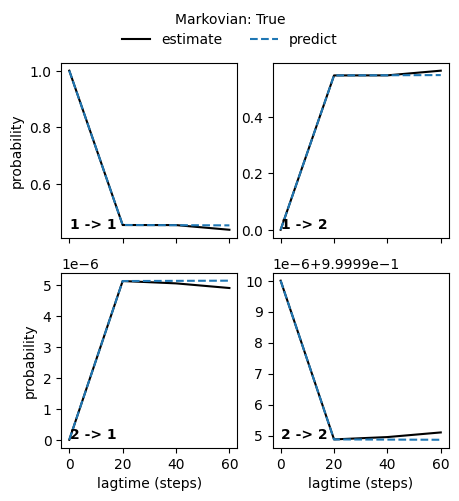

12 True
MSM construction error lagtime 60: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


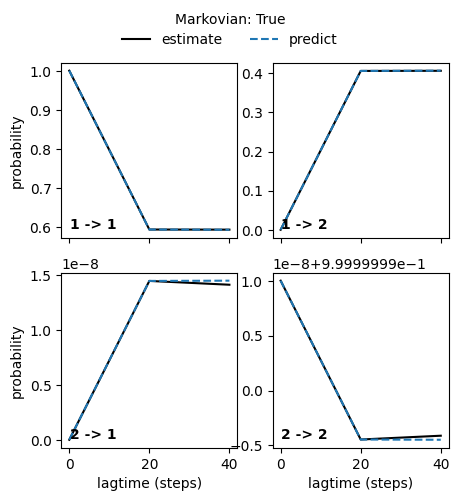

13 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


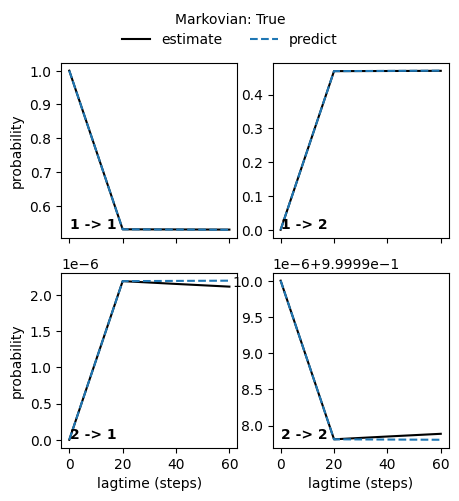

14 True


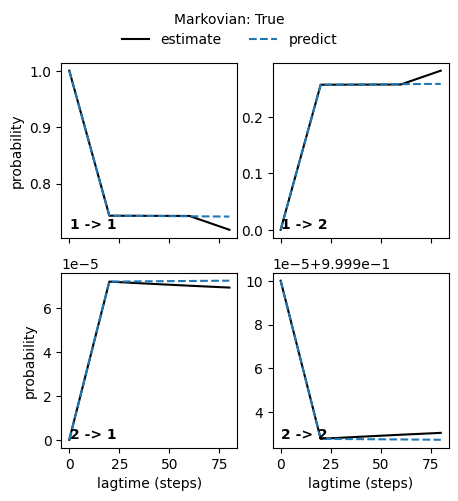

15 True


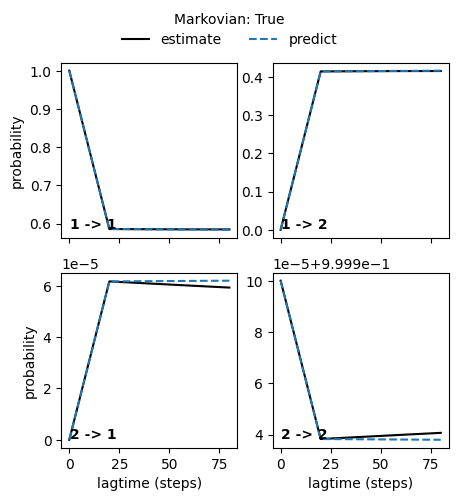

16 True


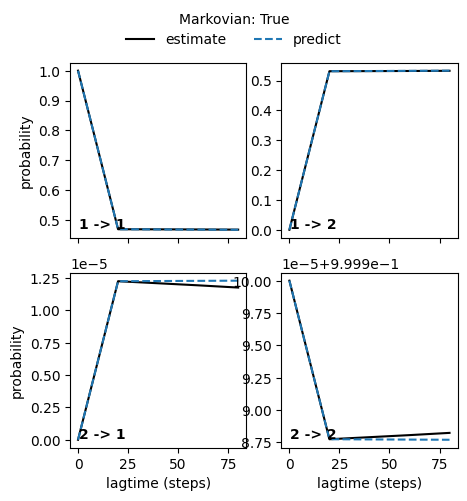

17 True


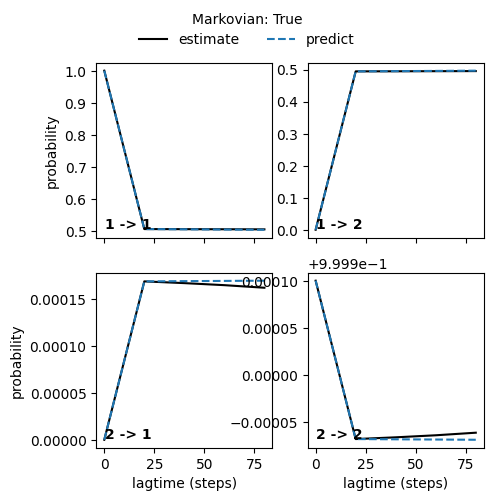

18 True


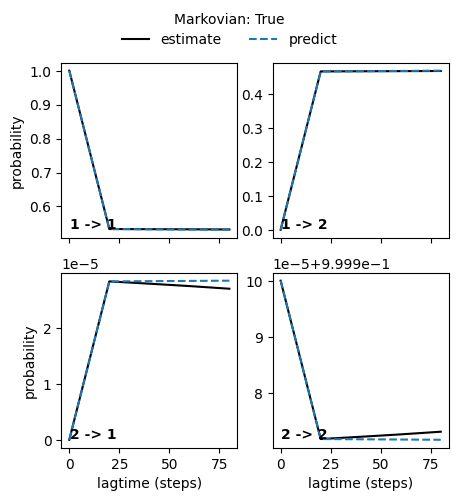

19 True


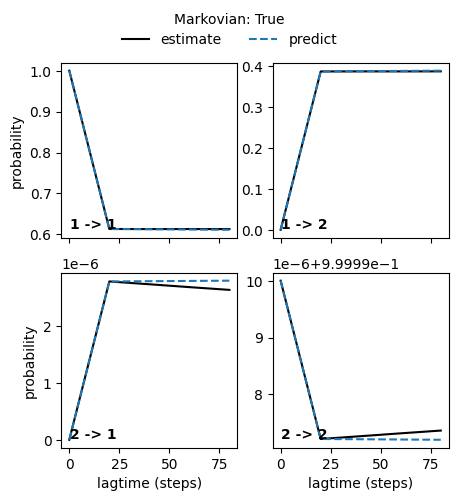

20 True


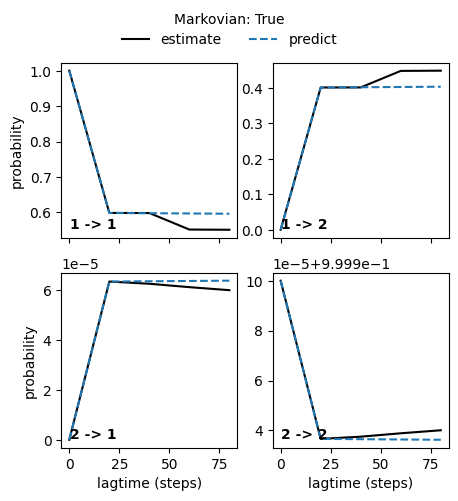

21 True


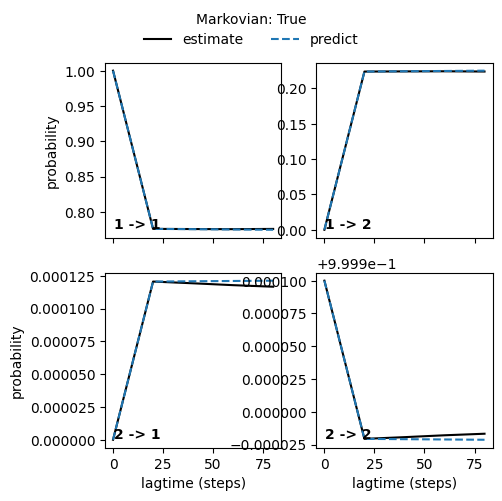

22 True


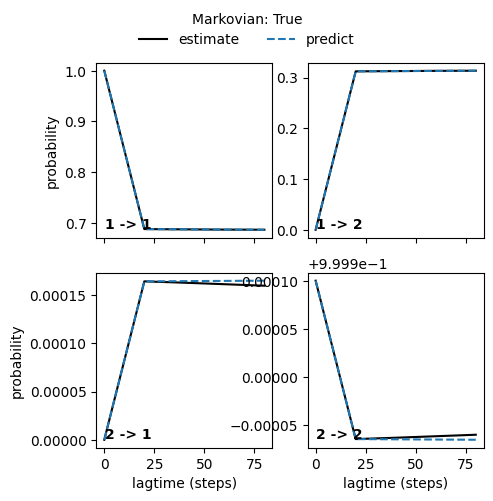

23 True


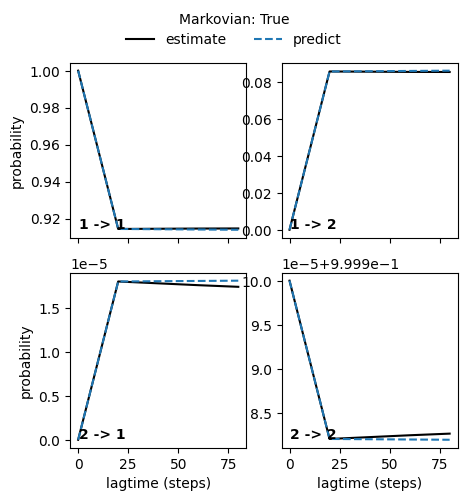

24 True


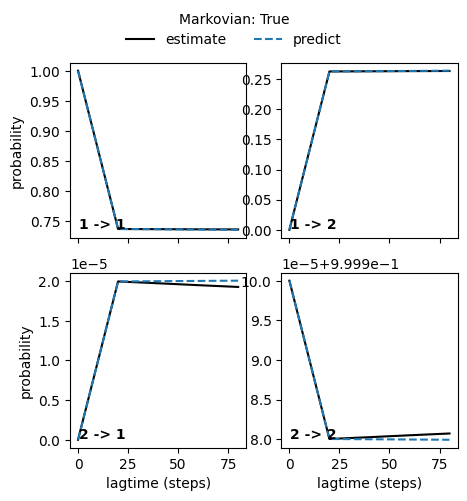

25 True


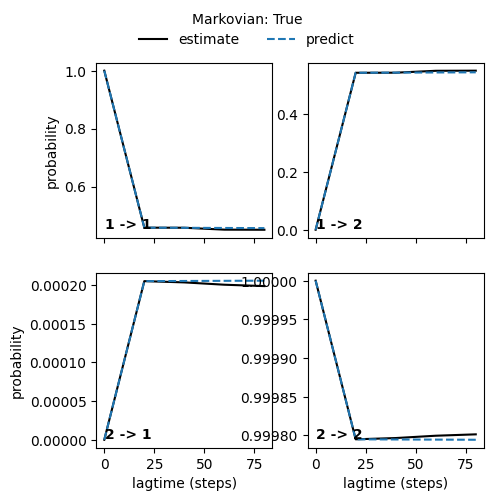

26 True


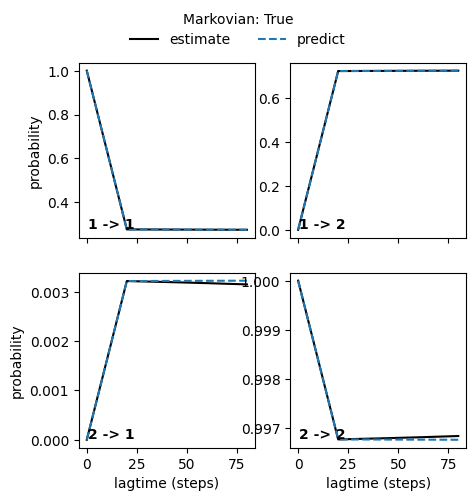

27 True


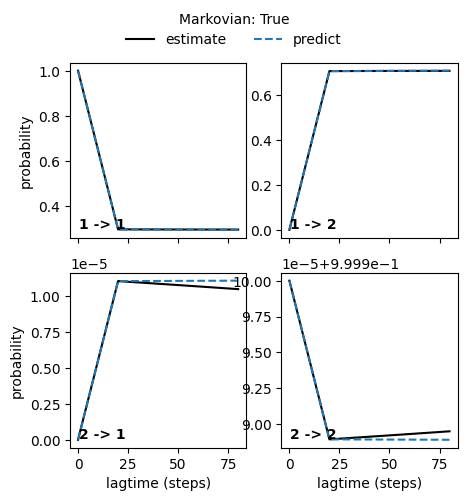

28 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


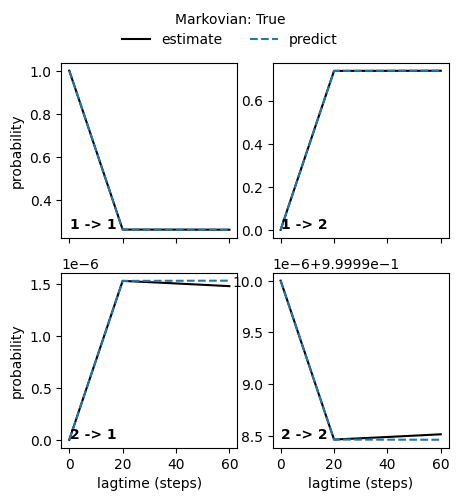

29 True


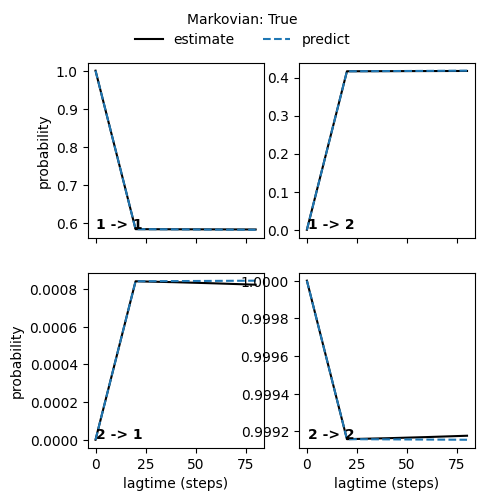

30 True


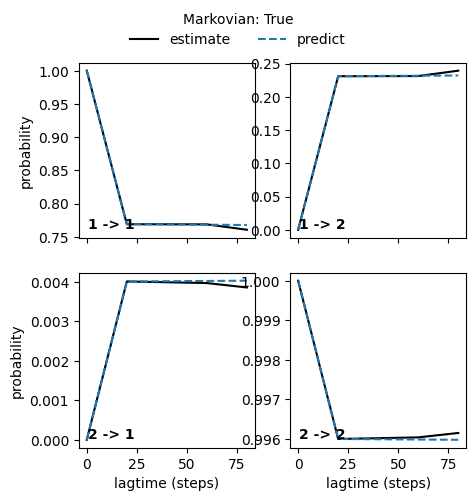

31 True


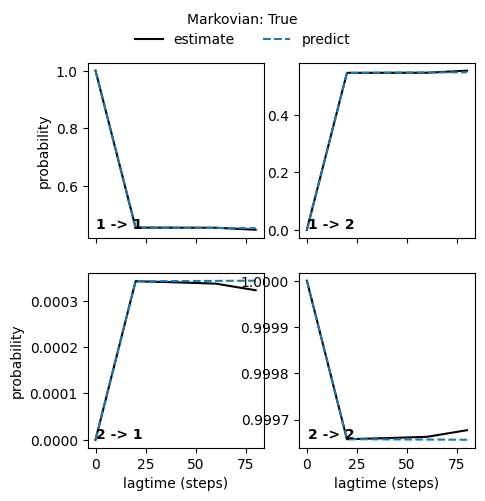

32 True


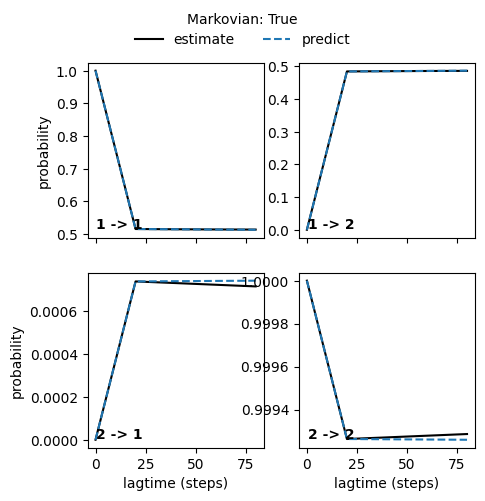

33 True


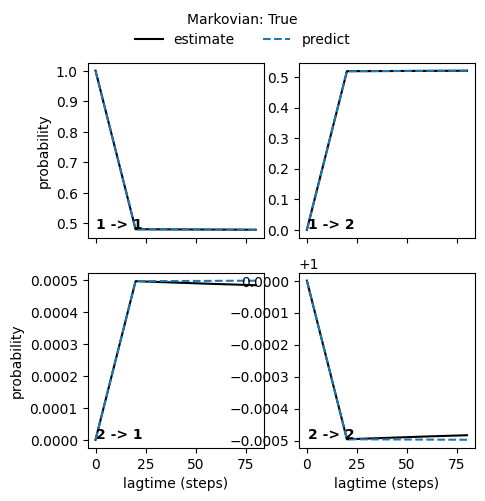

34 True


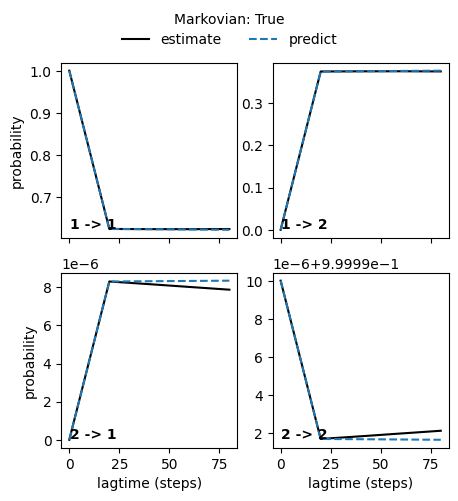

35 True


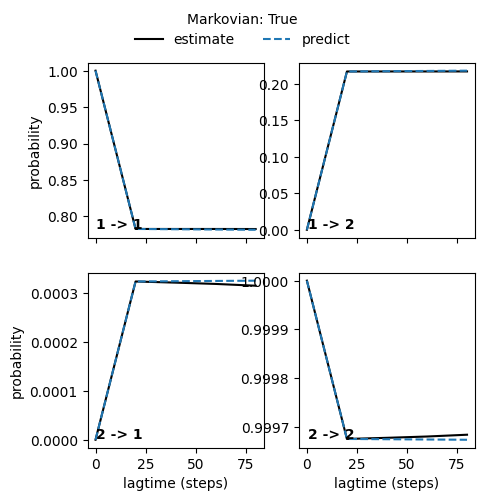

36 True


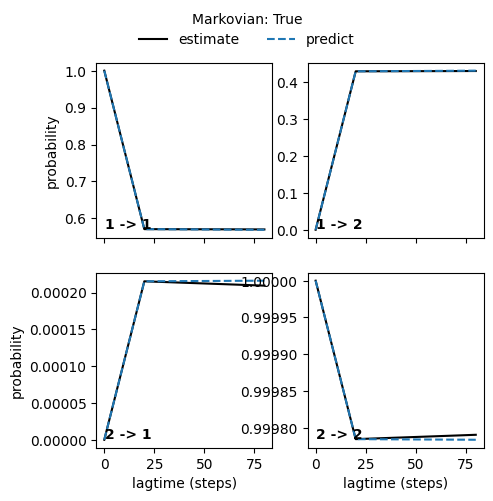

37 True


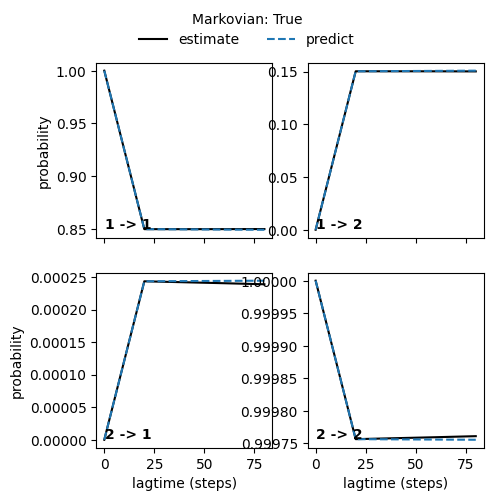

38 True


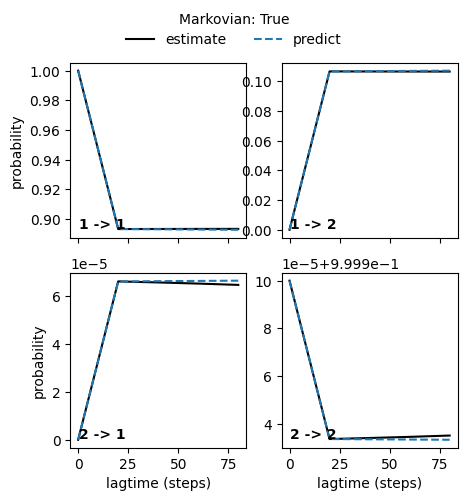

39 True


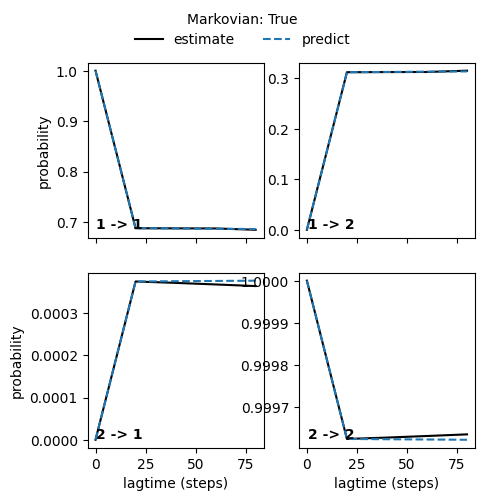

40 True


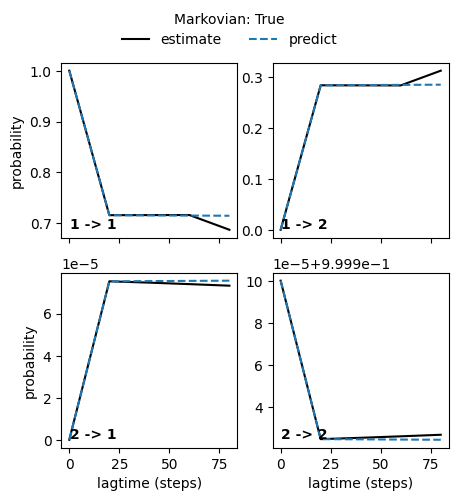

41 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


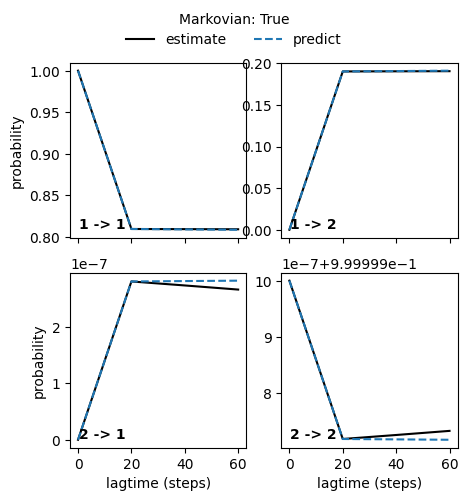

42 True


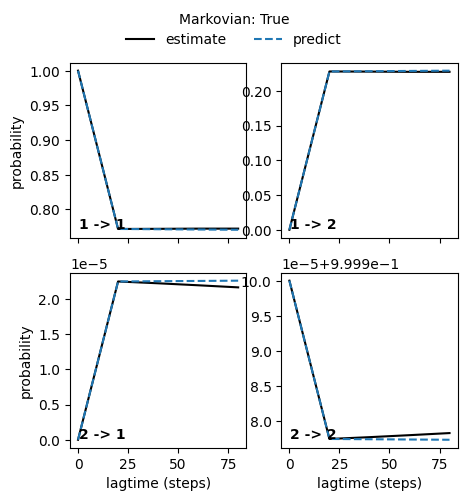

43 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


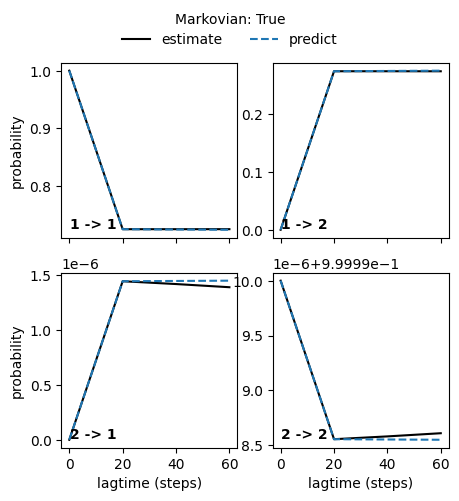

44 True
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


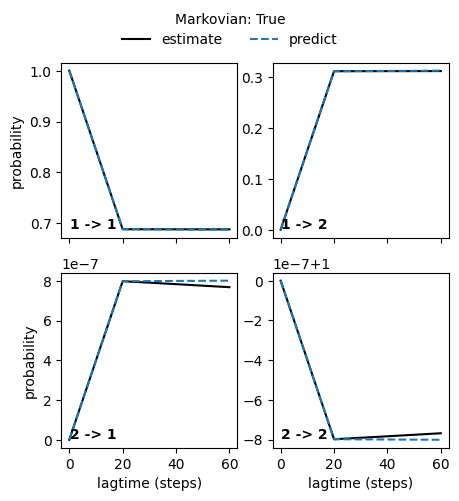

45 True
MSM construction error lagtime 60: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


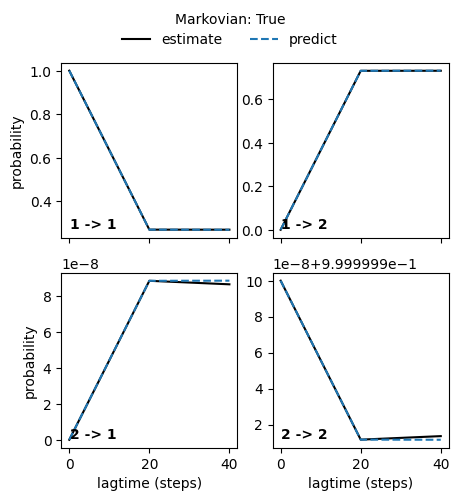

46 True


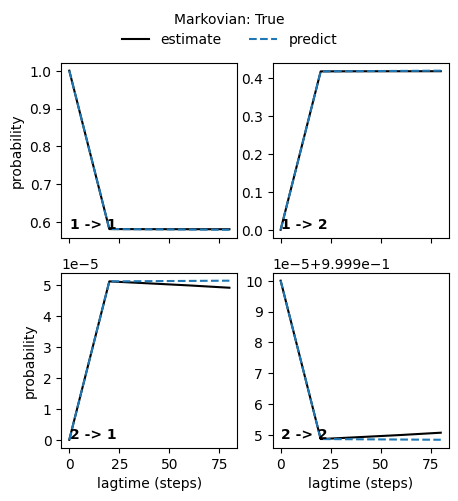

47 True


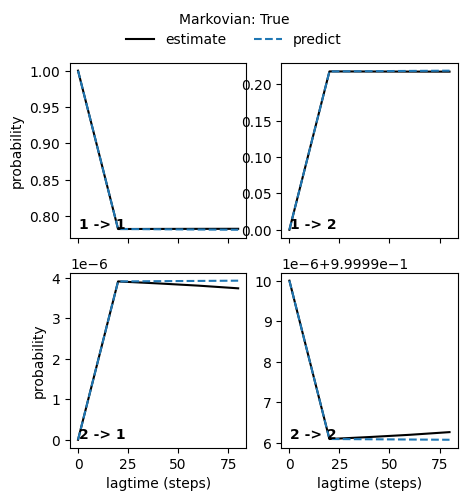

48 True
MSM construction error lagtime 60: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


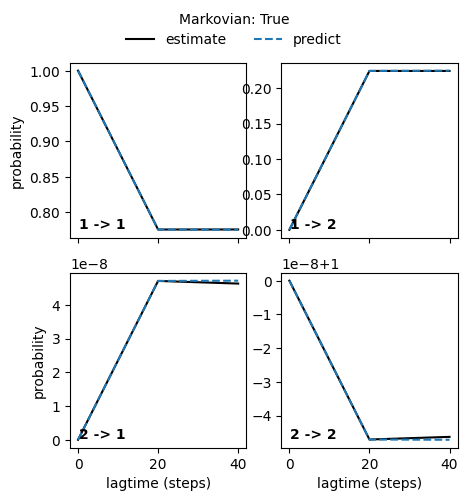

49 True


In [12]:
n_metastable_sets = 2
for trial in range(len(trajs)):
    print(trial, perform_ck_test(clustered_trajs[trial][N_CLUSTERS[trial]], msm_models[trial][N_CLUSTERS[trial]], None, None, LAGTIMES[trial], n_metastable_sets))

-8.041931604445676 1.7717345123969386
nan nan


/tmp/ipykernel_1353502/1971447245.py:32: RuntimeWarning: Mean of empty slice.
  print(gs[trial_groups_initial[1]].mean(), gs[trial_groups_initial[1]].std())
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


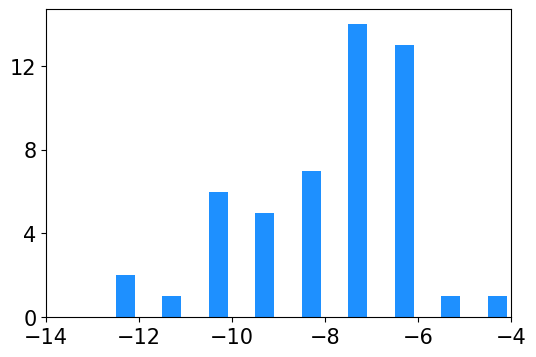

In [13]:
trial_groups_initial = [
    range(50),
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)


bins = np.arange(-15, 0)
centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

h0, _ = np.histogram(gs[trial_groups_initial[0]], bins=bins)
h1, _ = np.histogram(gs[trial_groups_initial[1]], bins=bins)

offset = bin_width * 0.2

ax.bar(centers + offset, h0, width=bin_width*0.4, color="#1E90FF")
ax.bar(centers - offset, h1, width=bin_width*0.4, color="tab:orange")

ax.set_xlim(-14, -4)

ax.set_xticks(range(-14, -2, 2))
ax.tick_params(axis='x', labelsize=15)
ax.set_yticks(range(0, 13, 4))
ax.tick_params(axis='y', labelsize=15)

print(gs[trial_groups_initial[0]].mean(), gs[trial_groups_initial[0]].std())
print(gs[trial_groups_initial[1]].mean(), gs[trial_groups_initial[1]].std())

-7.682977321873219 1.4135716601444193
-8.195769154119587 1.8839044120554822


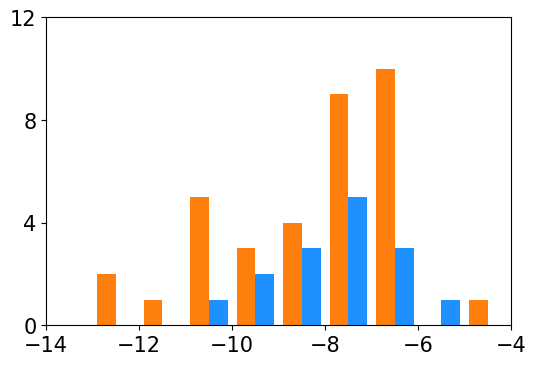

In [14]:
trial_groups_initial = [
    [0, 1, 2, 3, 4, 5, 6, 7, 9, 24, 25, 26, 27, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)


bins = np.arange(-15, 0)
centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

h0, _ = np.histogram(gs[trial_groups_initial[0]], bins=bins)
h1, _ = np.histogram(gs[trial_groups_initial[1]], bins=bins)

offset = bin_width * 0.2

ax.bar(centers + offset, h0, width=bin_width*0.4, color="#1E90FF")
ax.bar(centers - offset, h1, width=bin_width*0.4, color="tab:orange")

ax.set_xlim(-14, -4)

ax.set_xticks(range(-14, -2, 2))
ax.tick_params(axis='x', labelsize=15)
ax.set_yticks(range(0, 13, 4))
ax.tick_params(axis='y', labelsize=15)

print(gs[trial_groups_initial[0]].mean(), gs[trial_groups_initial[0]].std())
print(gs[trial_groups_initial[1]].mean(), gs[trial_groups_initial[1]].std())

-8.179570485296988 1.7467687152634293
-8.02316266614777 1.7742846616830092


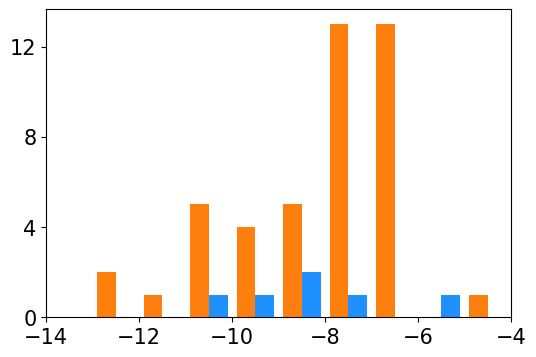

In [15]:
trial_groups_initial = [
    [4, 7, 25, 26, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)


bins = np.arange(-15, 0)
centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

h0, _ = np.histogram(gs[trial_groups_initial[0]], bins=bins)
h1, _ = np.histogram(gs[trial_groups_initial[1]], bins=bins)

offset = bin_width * 0.2

ax.bar(centers + offset, h0, width=bin_width*0.4, color="#1E90FF")
ax.bar(centers - offset, h1, width=bin_width*0.4, color="tab:orange")

ax.set_xlim(-14, -4)

ax.set_xticks(range(-14, -2, 2))
ax.tick_params(axis='x', labelsize=15)
ax.set_yticks(range(0, 13, 4))
ax.tick_params(axis='y', labelsize=15)

print(gs[trial_groups_initial[0]].mean(), gs[trial_groups_initial[0]].std())
print(gs[trial_groups_initial[1]].mean(), gs[trial_groups_initial[1]].std())

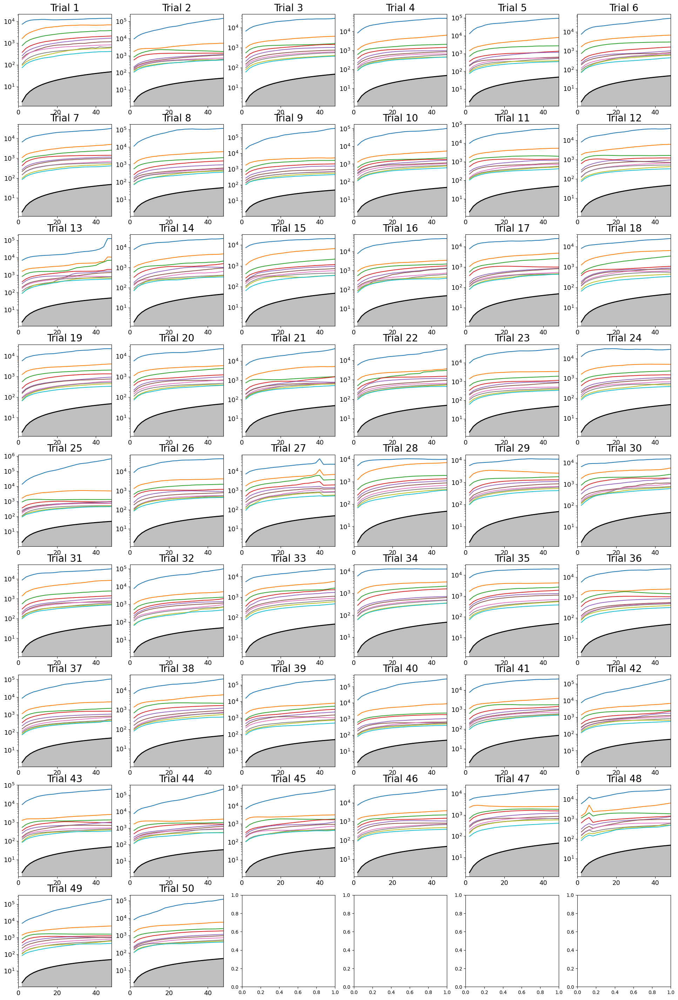

In [16]:
fig, ax = plt.subplots(9, 6)
fig.set_size_inches(24, 36)

for trial in range(len(trajs)):
    plot_implied_timescales(ax[trial//6, trial%6], msm_models[trial][N_CLUSTERS[trial]])
    ax[trial//6, trial%6].set_title(f"Trial {trial+1}", size=20)
    ax[trial//6, trial%6].tick_params(axis='x', labelsize=13)
    ax[trial//6, trial%6].tick_params(axis='y', labelsize=13)

MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 60: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


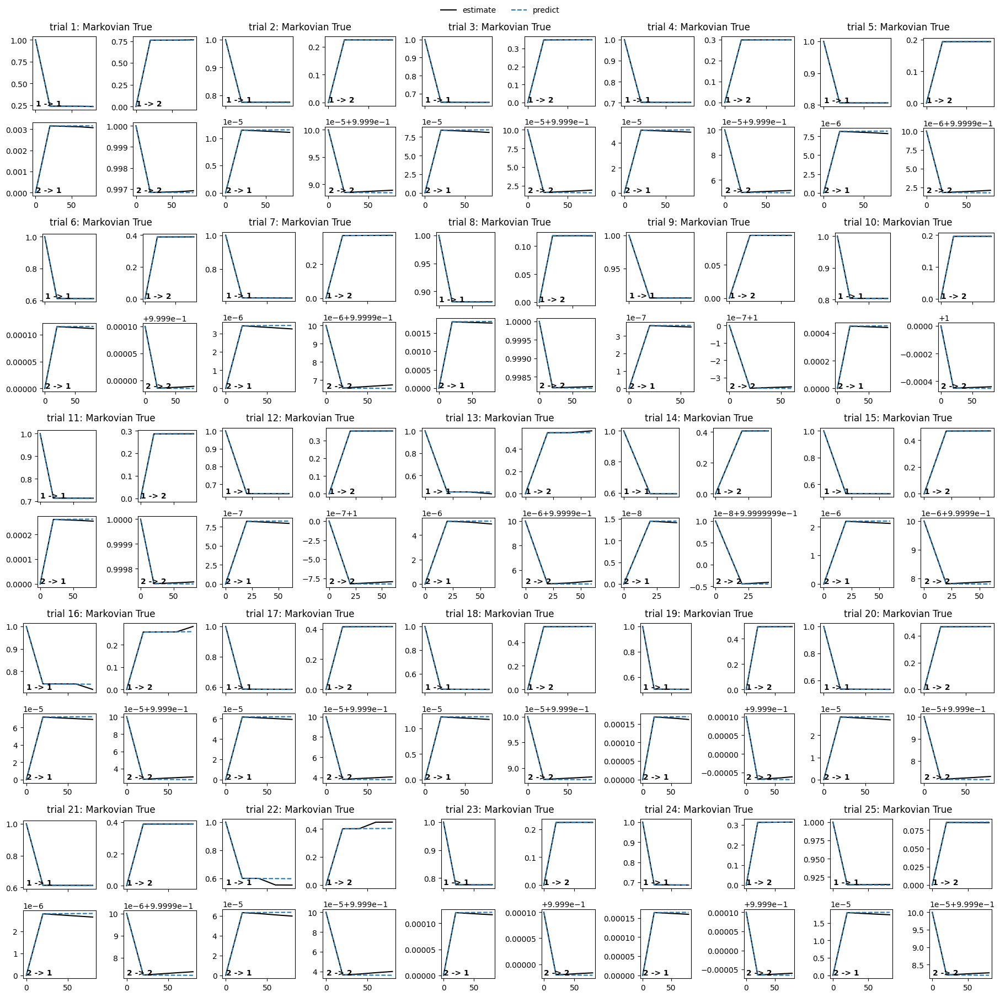

MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 60: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 60: Stationary distribution contains entries smaller than 0.000000 during iteration
MSM construction error lagtime 80: Stationary distribution contains entries smaller than 0.000000 during iteration


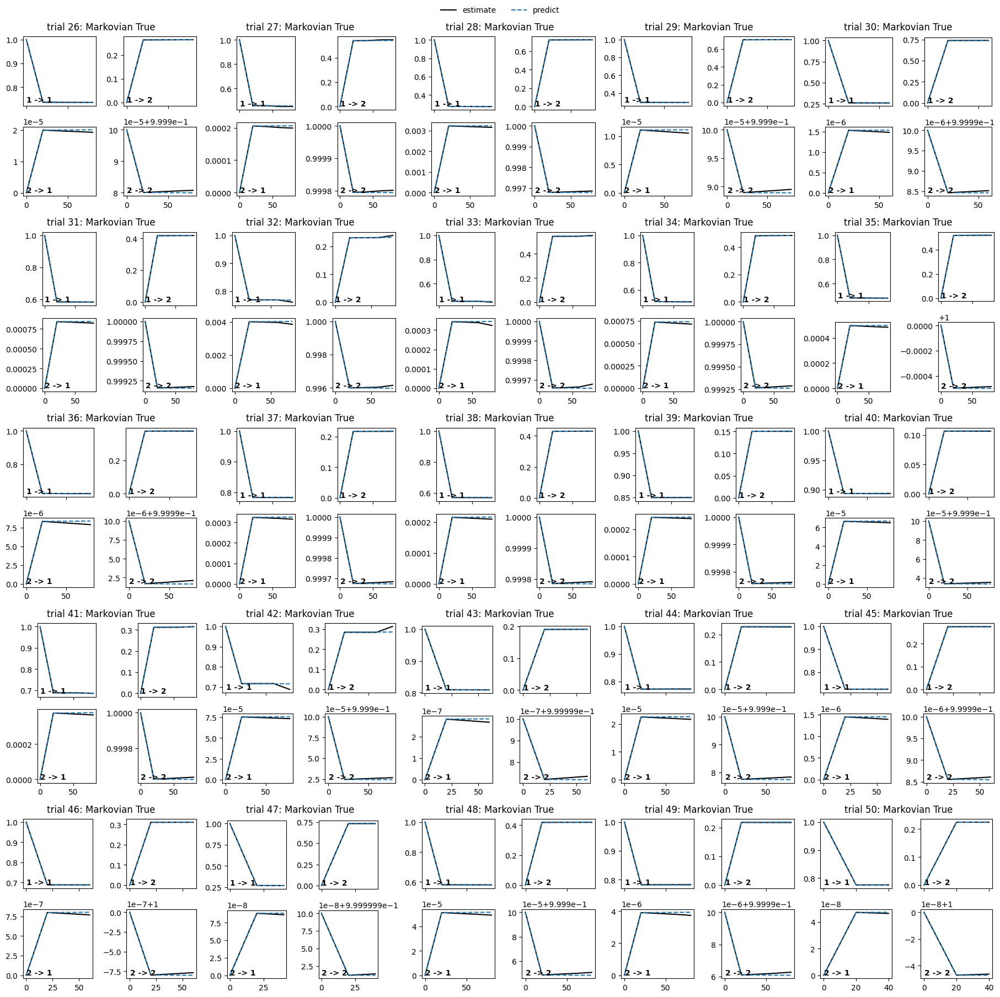

In [18]:
from deeptime.plots.chapman_kolmogorov import CKTestGrid


class CKTestGridOnAxes(CKTestGrid):
    def __init__(self, axes):
        self._n_cells_x = self._n_cells_y = axes.shape[0]
        self._axes = axes
        self._figure = axes[0, 0].figure
        self._sharey = False
        self._tests, self._lest_handles, self._lpred_handles = [], [], []


n_metastable_sets = 2
tolerance = 0.05
nrows, ncols = 5, 5

for trials in (range(0, 25), range(25, 50)):
    fig = plt.figure(figsize=(ncols*3.6, nrows*3.6), layout="constrained")
    subfigs = fig.subfigures(nrows, ncols).ravel()
    for subfig, trial in zip(subfigs, trials):
        lagtime = LAGTIMES[trial]
        ck_models, _ = construct_msm(clustered_trajs[trial][N_CLUSTERS[trial]], [lagtime*k for k in range(1, 5) if lagtime*k < N_TIMESTEP_IN_REPLICA - 1])
        if len(ck_models) < 2:
            subfig.suptitle(f"trial {trial+1}: Markovian None")
            continue
        ck_test = msm_models[trial][N_CLUSTERS[trial]][lagtime].ck_test(list(ck_models.values()), n_metastable_sets=n_metastable_sets)

        differences = np.real(ck_test.predictions - ck_test.estimates)[lagtime < ck_test.lagtimes]
        is_markovian = bool(np.all(np.abs(differences) <= tolerance))

        axes = subfig.subplots(n_metastable_sets, n_metastable_sets, sharex=True, squeeze=False)
        deeptime.plots.plot_ck_test(ck_test, grid=CKTestGridOnAxes(axes), legend=False, xlabel=None, ylabel=None, y01=False)
        subfig.suptitle(f"trial {trial+1}: Markovian {is_markovian}")
    fig.legend(handles=[Line2D([], [], color="black", label="estimate"), Line2D([], [], color="C0", ls="--", label="predict")], loc="outside upper center", ncols=2, frameon=False)
    plt.show()